# Trabajo Práctico  - Calibración y Pose de la Cámara

## Resolución

## GRUPO: MEDJ

# Integrantes
* Matías Agustín Tabak Wolf (273/24)
* Elking Richelieu Mendoza Zambrano (118/25)
* Dante Fongi Martínez (799/24)
* Joaquin Bernardez (959/23)

In [16]:
import alc
import numpy as np
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

### Ejercicio 1 - DLT ecuaciones formales

Siendo $Q\in \mathbb{R}^{2n\times 12}$, ¿qué rango debe tener para asegurar una solución no nula única a menos de un factor de escala? ¿Cuántos puntos, como mínimo, aseguran la solución y qué condición deben cumplir?

Encontrar el vector $\mathbf{m}$ que resuelve la minimización de la ecuación 6.

**Sistema de la ecuación 6** *(está desarrollado para todas las imágenes pero se puede quitar el for i y determinar un i específico para formar la $\mathbf{Q}$ de una sola foto)*

In [17]:
detected_corners_path = os.path.join('calib','3d','detected_corners.txt')
p_W_corners_path = os.path.join('calib','3d','p_W_corners.txt')

corners = np.loadtxt(p_W_corners_path,delimiter=',')
G = np.loadtxt(detected_corners_path)

corners

array([[  0.  ,   8.  ,   0.  ],
       [ 10.4 ,   8.  ,   0.  ],
       [  0.  ,  21.5 ,   0.  ],
       [ 10.4 ,  21.5 ,   0.  ],
       [  0.  ,  26.6 , -10.95],
       [ 10.4 ,  26.6 , -10.95],
       [  0.  ,  26.6 , -24.45],
       [ 10.4 ,  26.6 , -24.45],
       [ 19.4 ,  14.6 , -10.95],
       [ 19.4 ,  14.6 , -24.45],
       [ 19.4 ,  25.  , -10.95],
       [ 19.4 ,  25.  , -24.45]])

<u>**Primer pregunta**</u>

Para responderla recurrimos al siguiente teorema:

* **Teorema de Rango-Nulidad** $\longrightarrow$ Sean $V$ y $W$ espacios vectoriales con $dim(V) < +\infty$ y sea $T:V \longrightarrow W$ una transformación lineal entonces $dim(Im(T)) + dim(Nu(T)) = dim(V)$

Considerando que debemos asegurar que hay una solución no nula única a menos de un factor de escala (esto último no interfiere en la consideración del teorema y respuesta del enunciado ya que el conjunto de soluciones es un subespacio y por lo tanto considera a todos sus múltiplos, con hallar una es suficiente y mantiene la propiedad de ser única), sabemos entonces que la $dim(Nu(\mathbf{Q})) = 1$, luego por el teorema podemos despejar $dim(Im(\mathbf{Q}))$, que es quien responde a la pregunta del rango. Por lo mencionado, podemos decir que $dim(Im(\mathbf{Q})) = dim(V) - dim(Nu(\mathbf{Q})) = dim(V) - 1 = 12 - 1 = 11$. El rango que debe tener $\mathbf{Q}$ para asegurar una solución no nula única a menos de un factor de escala es 11.

¿Quien es $V$? ¿Por qué $dim(V) = 12$? Podemos definir a $T$, la transformación lineal que representa nuestra matriz $\mathbf{Q}$, tal que (por las dimensiones de $\mathbf{Q}$) vemos que toma elementos de $R^{12}$ y los lleva a $R^{2n}$, siendo entonces $T:R^{12} \longrightarrow R^{2n}$. Por ello, el espacio de salida es $V = R^{12}$ y $dim(R^{12}) = 12$ $\Longrightarrow$ $dim(V) = 12$.

<u>**Segunda pregunta**</u>

¿Cuántos puntos, como mínimo, aseguran la solución? Prestando atención a esta parte de la pregunta vemos que la misma también se traduce a cuantas filas necesitamos como mínimo para que la respuesta de la anterior pregunta sea válida (o sea, $dim(Im(\mathbf{Q})) = 11$ y, por lo tanto, $dim(Nu(\mathbf{Q})) = 1$) ¿Por qué filas si nos preguntan puntos? Porque cada par de filas en la matriz $\mathbf{Q}$ representa un punto, y además sabemos que el rango de una matriz (que es igual a la dimensión de la imagen de la matriz) es mayor o igual a uno y menor o igual a la cantidad de filas de ella. Por lo que podemos concluir que $dim(Im(\mathbf{Q})) = 11 \leq 2n$, más específicamente: $\frac{11}{2} = 5.5 \leq n$. Entonces (considerando que $n$ es un número natural) la cantidad de puntos mínimos que aseguran la solución son $6$. 

¿Y qué condición deben cumplir? Como $dim(Im(\mathbf{Q})) = 11$ entonces sabemos que las filas deben de ser linealmente independientes entre sí, ya que le hallamos un techo al decir que $n = 6$ por lo menos, pero también debemos garantizar su piso para que la dimensión del núcleo no crezca (ya que de esa manera perderiamos la condición $dim(Nu(\mathbf{Q})) = 1$ y sería mayor a uno). Para ello, la matriz $\mathbf{Q}$ es una matriz que tiene 11 filas necesariamente linealmente independientes. Traduciendo esa información a los puntos $U,V,W$ logramos entender que será necesario que hayan 6 puntos no coplanares, o sea que hayan 6 puntos distribuidos de tal manera que no exista un plano que pueda contenerlos a la vez.

<u>**Hallar el vector**</u> $\mathbf{m}$

Sea $Q = U \Sigma V^*$ su descomposición SVD.

$\min\limits_{\mathbf{m}}$ $\|\mathbf{Qm}\|^2$ = $\min\limits_{\mathbf{m}}$ $\|U \Sigma V^* m\|^2$

Dado que $U$ y $V^*$ son unitarias sabemos que $\|\mathbf{Ux}\| = \|\mathbf{x}\|$ y $\|\mathbf{V^*x}\| = \|\mathbf{x}\|$ $\forall x \in R^n$, por lo que podemos reescribir la anterior expresión de la siguiente manera

$\min\limits_{\mathbf{m}}$ $\|\Sigma V^* m\|^2$

Definiendo $y = V^* m$, podemos concluir que $\|y\| = \|V^* m\| = \|m\| = 1$ pues, por enunciado, $\|m\| = 1$. Entonces lo anterior es igual a 

$\min\limits_{\mathbf{y}}$ $\|\Sigma y\|^2$

Como $\|y\| = 1$, $\sigma_n$ es el valor singular más pequeño en $\Sigma$ y nos interesa hallar el vector que minimice la expresión, podemos considerar $y = \mathbf{e_{12}}$, quedando como resultado de la multiplicacion $\Sigma y$, el vector $(0,...,\sigma_n)$.

Volviendo a nuestra reescritura previa obtenemos que $V^* m = \mathbf{e_{12}}$, por lo que el $m$ deseado que minimiza la ecuación 6 es $m = V\mathbf{e_{12}} = v_n$ (siendo $v_n$ la columna $n$ de la matriz $V$).

Sabemos que $V^*$ unitaria $\Longrightarrow V$ es unitaria. Lo anterior quiere decir que las columnas de $V$ también forman una $BON$ (Base Ortonormal), por lo que cada columna tiene norma igual a uno y vale que $\|m\| = \|v_n\| = 1$.

$\therefore$ El $m$ que resuelve $\min\limits_{\mathbf{m}} \|\mathbf{Qm}\|^2$ es $m = v_n$

### Ejercicio 2 - Calibración con puntos 3D

Item a)

In [38]:
Q_3d = alc.obtenerQ3d(G[0], corners)

In [39]:
M_3d = alc.resolverDLT3D(Q_3d)


In [56]:
R_3d, t_3d, K_3d = alc.devolverMatricesCalibracion3d(M_3d)

print(f"R:\n{R_3d}")
print(f"\nt:\n{t_3d}")
print(f"\nK:\n{K_3d}") # tol está por ^-15

R:
[[ 0.618213    0.12921397 -0.77531699]
 [-0.35508353  0.92591643 -0.12881947]
 [ 0.70123346  0.35494017  0.61829533]]

t:
[-18.1679383  -14.50326886  40.5912892 ]

K:
[[ 4.25859863e+02 -1.56351762e-02  3.54418499e+02]
 [-0.00000000e+00  4.24565307e+02  2.56853355e+02]
 [-0.00000000e+00 -0.00000000e+00  1.00000000e+00]]


b)

In [54]:
R_3d_b, t_3d_b, K_3d_b = alc.devolverMatricesCalibracion3d(M_3d,op=(False,True))
K_3d_b

array([[ 4.25212585e+02, -1.56351762e-02,  3.54418499e+02],
       [-0.00000000e+00,  4.25212585e+02,  2.56853355e+02],
       [-0.00000000e+00, -0.00000000e+00,  1.00000000e+00]])

C)

In [55]:
R_3d_c, t_3d_c, K_3d_c = alc.devolverMatricesCalibracion3d(M_3d,op=(True,False))
K_3d_c

array([[425.8598626 ,   0.        , 354.41849864],
       [ -0.        , 424.56530706, 256.85335529],
       [ -0.        ,  -0.        ,   1.        ]])

### Ejercicio 3 - Calibración con puntos coplanares

Resolver la calibración para el caso de puntos coplanares, trabajando sobre los datos de la carpeta $\texttt{calib/coplanar}$ con las imágenes $\texttt{Im\_R\_1.png}$ a $\texttt{Im\_R\_20.png}$.


a) Obtener la matriz $\mathbf{K}$

b) Encontrar la pose de $\texttt{Im\_R\_1.png}$, $\texttt{Im\_R\_10.png}$ y $\texttt{Im\_R\_20.png}$.

In [23]:
def obtenerQ2d(imgPts, objPts):
    """
    Construcción de la matriz Q para el cálculo de homografía H
    Recibe un arreglo 1D imgPts y un arreglo 2D objPts 
    y retorna la matriz Q preasignada de dimensiones 2N x 9.
    """
    U, V = objPts[:, 0], objPts[:, 1]
    N = objPts.shape[0]
    
    Q = np.zeros((2 * N, 9))
    
    for j in range(N):
        u = imgPts[2*j]
        v = imgPts[2*j+1]
        
        Q[2*j, :]   = [U[j], V[j], 1,   0,    0,  0,  -u*U[j], -u*V[j], -u]
        Q[2*j+1, :] = [ 0,    0,   0, U[j], V[j], 1,  -v*U[j], -v*V[j], -v]
        
    return Q

In [24]:
def armarA(Hlst):
    n = len(Hlst)
    A = np.zeros((2 * n, 6))
    
    for i, H in enumerate(Hlst):
        c1, c2 = H[:, 0], H[:, 1]
        
        A[2*i, :] = [c1[0]*c2[0], c1[0]*c2[1] + c1[1]*c2[0], c1[1]*c2[1], c1[2]*c2[0] + c1[0]*c2[2], c1[2]*c2[1] + c1[1]*c2[2], c1[2]*c2[2]]

        A[2*i + 1, :] = [c1[0]*c1[0] - c2[0]*c2[0],
                         c1[0]*c1[1] + c1[1]*c1[0] - c2[0]*c2[1] - c2[1]*c2[0],
                         c1[1]*c1[1] - c2[1]*c2[1],
                         c1[2]*c1[0] + c1[0]*c1[2] - c2[2]*c2[0] - c2[0]*c2[2],
                         c1[2]*c1[1] + c1[1]*c1[2] - c2[2]*c2[1] - c2[1]*c2[2],
                         c1[2]*c1[2] - c2[2]*c2[2]]
                         
    return A

In [25]:
######## K2D ---------- SIN SVD -------------------- 

def calcularMatrizK2D(A):
    '''
    Calcula K a partir de A (2N x 6) por el método de Zhang.
    Resuelve min ||A b|| con ||b|| = 1, arma B simétrica, elige el signo para que B
    sea definida positiva, factoriza B = L L^T (Cholesky) y devuelve K = (L^T)^{-1} con K[2,2] = 1.
    '''
    # min ||A b||: autovector de A^T A con el menor autovalor (sin descartar ninguno)
    AtA = alc.arroba(alc.transpuesta(A), A)
    AtA = AtA / np.max(np.abs(AtA))          # escalado: no cambia los autovectores
    S, D = alc.diagRH(AtA, 1e-12, K=1000)
    i_min = 0
    for i in range(6):
        if D[i, i] < D[i_min, i_min]:
            i_min = i
    b = S[:, i_min]                          # COLUMNA de S

    B = np.array([[b[0], b[1], b[3]],
                  [b[1], b[2], b[4]],
                  [b[3], b[4], b[5]]])
    if not alc.esSDP(B):
        B = (-1) * B
    if not alc.esSDP(B):
        raise ValueError('B no es definida positiva: no se puede aplicar Cholesky.')

    L = alc.calculaCholesky(B)
    K = alc.inversa(alc.transpuesta(L))
    return K / K[2, 2]



In [26]:


def resolverDLT2D(A):
    '''
    Parámetros que recibe:
    Que retornará:
    (Recordar comentar el código y dar a las variables nombres explicativos)
    '''
    hatU, hatSig, hatV = alc.svd_reducida(A)
    M = hatV[:,-1]
    M = np.reshape(M,(3,3))
    return M

In [27]:
def obtenerPose2D(Hj, K):
    '''
    Recupera la pose (R, t) de una vista a partir de su homografía Hj = s K [r1 r2 t]
    (sección 2.2, paso h) y de la matriz de intrínsecos K.
    Recibe: Hj (3x3, plano -> imagen) y K (3x3).
    Retorna: Rj (3x3, rotación con det = +1) y tj (3), en las unidades del plano.
    '''
    Kinv = alc.inversa(K)

    # Columnas de K^{-1} H: proporcionales a r1, r2 y t
    KinvC1 = alc.arroba(Kinv, Hj[:, 0])
    KinvC2 = alc.arroba(Kinv, Hj[:, 1])
    KinvC3 = alc.arroba(Kinv, Hj[:, 2])

    # Escala: ||r1|| = 1
    λ = 1 / alc.norma(KinvC1, 2)

    # Signo: H está definida a menos de signo; elegimos el que deja el plano delante de la cámara
    if λ * KinvC3[2] < 0:
        λ = -λ

    r1 = λ * KinvC1
    r2 = λ * KinvC2
    tj = λ * KinvC3

    # r3 = r1 x r2 (producto vectorial)
    r3 = np.array([r1[1]*r2[2] - r1[2]*r2[1],
                   r1[2]*r2[0] - r1[0]*r2[2],
                   r1[0]*r2[1] - r1[1]*r2[0]])

    R_aprox = np.zeros((3, 3))
    R_aprox[:, 0], R_aprox[:, 1], R_aprox[:, 2] = r1, r2, r3

    # Por el ruido, R_aprox no es exactamente ortogonal: la ortonormalizamos con QR.
    # La QR es única a menos de signos de las columnas: pedimos diagonal de R_qr positiva,
    # para que Q no invierta ninguna columna respecto de R_aprox.
    Q, R_qr = alc.QR_con_HH(R_aprox)
    for k in range(3):
        if R_qr[k, k] < 0:
            Q[:, k] = (-1) * Q[:, k]
    Rj = Q



    return Rj, tj

In [28]:
def normalizacionIsotropica2D(puntos):
    """
    Aplica normalización de Hartley a una matriz de puntos 2D de dimensiones (N, 2).
    Retorna los puntos normalizados y la matriz de transformación T (3x3).
    """
    N = puntos.shape[0]
    
    # Cálculo del centroide
    cx = np.sum(puntos[:, 0]) / N
    cy = np.sum(puntos[:, 1]) / N

    # Traslación al origen
    puntos_centrados = np.zeros_like(puntos, dtype=float)
    puntos_centrados[:, 0] = puntos[:, 0] - cx
    puntos_centrados[:, 1] = puntos[:, 1] - cy

    # Cálculo de la distancia media al origen
    distancias = np.sqrt(puntos_centrados[:, 0]**2 + puntos_centrados[:, 1]**2)
    distancia_media = np.sum(distancias) / N

    # Factor de escala
    if distancia_media > 0:
        escala = np.sqrt(2.0) / distancia_media
    else:
        escala = 1.0

    # Aplicación de la escala
    puntos_norm = puntos_centrados * escala

    # Construcción de la matriz de transformación T
    T = np.array([
        [escala, 0,      -escala * cx],
        [0,      escala, -escala * cy],
        [0,      0,      1.0         ]
    ])

    return puntos_norm, T

In [57]:
oP_ej_3 = np.array([[0,0],[90,0],[90,60],[0,60],[30,90]])

# Imagen 1 
iP_img_1 = np.array([369,326,491,353,493,271,371,270,412,229])

# Imagen 10
iP_img_10 = np.array([397,332,529,325,523,239,394,246,436,202])

# Imagen 20 
iP_img_20 = np.array([404,348,535,342,533,254,400,258,444,212])

imagenes = np.array([iP_img_1,iP_img_10 ,iP_img_20])






# 1. Normalización de los puntos de la geometría (Z=0)
oP_norm_ej_3, T_obj_ej_3 = normalizacionIsotropica2D(oP_ej_3)

Hlst_img_ej_3 = []

for img in imagenes:    
    Q_ej_3 = alc.obtenerQ2d(img, oP_ej_3)
    
    # 1. Escalado base (100% legal) para evitar que Q^T Q explote y destruya diagRH
    Q_ej_3 = Q_ej_3 / np.max(np.abs(Q_ej_3))
    
    # 2. Diagonalizar directamente Q^T Q esquivando el recorte automático de svd_reducida
    QtQ_ej_3 = alc.arroba(alc.transpuesta(Q_ej_3), Q_ej_3)
    S_Q_ej_3, D_Q_ej_3 = alc.diagRH(QtQ_ej_3, 1e-12, 1000)
    
    # 3. Extraer el autovector del MENOR autovalor (Igual a tu excelente lógica en calcularMatrizK2D)
    i_min_q = 0
    for i in range(9):
        if D_Q_ej_3[i, i] < D_Q_ej_3[i_min_q, i_min_q]:
            i_min_q = i
            
    # 4. Formar la homografía real y matemáticamente pura
    Hk_ej_3 = np.reshape(S_Q_ej_3[:, i_min_q], (3, 3))
    Hlst_img_ej_3.append(Hk_ej_3)

A_ej_3 = armarA(Hlst_img_ej_3)
print(A_ej_3.shape)
K_ej_3 = calcularMatrizK2D(A_ej_3)

poses = []

for H in Hlst_img_ej_3:
    R_ej_3, t_ej_3 = obtenerPose2D(H, K_ej_3)
    poses.append([R_ej_3, t_ej_3])

print(poses)


(6, 6)


ValueError: B no es definida positiva: no se puede aplicar Cholesky.

### Ejercicio 4 - Fútbol

a) Calcular la homografía de la cancha de futbol de la foto de $\texttt{gol-enzo.png}$. Encontrar la distancia a la que se encontraba Enzo. 
    Dibujar sobre la fotografía círculos de 1 metro de diámetro alrededor de los jugadores argentinos.

b) Calcular la homografía de la changa de fútbol de la foto $\texttt{posibleoffside.jpg}$. 
    Trazar sobre la fotografía una recta sobre el pié del jugador del equipo defensor que defina si hay fuera de juego.
    

In [ ]:
iP_ej_4 = np.array([193,171,841,190,154,232,869,251,511,318,386,177,652,185])
oP_ej_4 = np.array([[105,43.16],[105,24.8],[99.5,43.16],[99.5,24.8],[94,34],[105,37.66],[105,30.34]])

Q_ej_4 = alc.obtenerQ2d(iP_ej_4,oP_ej_4)

H_ej_4 = alc.resolverDLT2D(Q_ej_4)

Hinv_ej_4 = alc.inversa(H_ej_4)

v_ej_4 = alc.arroba(Hinv_ej_4, np.array([813,546,1]))
v_ej_4 = v_ej_4/v_ej_4[2]

print("Item a)")
print(f'Posición de Enzo: {v_ej_4[0:2]}')

d_ej_4 = (np.array([105,30.34,1]) - v_ej_4)
res_ej_4 = alc.norma(d,2)
print(f"Distancia de Enzo al arco: {res_ej_4}")

Item a)
Posición de Enzo: [82.5357867  28.24002863]
Distancia de Enzo al arco: 22.562153243330364


In [ ]:
# ITEM B) 

j1 = alc.arroba(Hinv_ej_4, np.array([101,534,1]))
j2 = alc.arroba(Hinv_ej_4, np.array([243,403,1]))
j3 = alc.arroba(Hinv_ej_4, np.array([376,324,1]))
j4 = alc.arroba(Hinv_ej_4, np.array([382,295,1]))
j5 = alc.arroba(Hinv_ej_4, np.array([844,349,1]))
j6 = alc.arroba(Hinv_ej_4, np.array([813,546,1]))

j1 = j1/j1[2]
j2 = j2/j2[2]
j3 = j3/j3[2]
j4 = j4/j4[2]
j5 = j5/j5[2]
j6 = j6/j6[2]

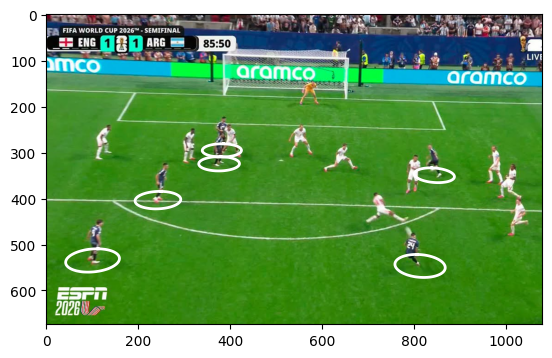

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Tu lectura que convierte BGR a RGB mediante slicing
img = cv2.imread('futbol/test-gol-enzo.png')[:, :, ::-1]

# 1. Definir los ángulos para los bordes del círculo
theta = np.linspace(0, 2 * np.pi, 100)

# 2. Cargar tu imagen de fondo
plt.imshow(img)

# 3. Agrupar los vectores (X, Y, 1) que ya calculaste en la cancha
jugadores = [j1, j2, j3, j4, j5, j6]

for j in jugadores:
    # Generamos los puntos del círculo de radio 1 metro en la cancha
    pts_X_cancha = j[0] + 1 * np.cos(theta)
    pts_Y_cancha = j[1] + 1 * np.sin(theta)
    unos = np.ones_like(pts_X_cancha)
    
    # Matriz homogénea del círculo en la cancha (3 filas x 100 columnas)
    circulo_cancha = np.array([pts_X_cancha, pts_Y_cancha, unos])
    
    # Proyectamos los puntos hacia la foto usando la matriz de homografía directa H
    circulo_img = alc.arroba(H, circulo_cancha)
    
    # Normalizamos dividiendo las coordenadas proyectadas por el factor de escala w
    u_img = circulo_img[0, :] / circulo_img[2, :]
    v_img = circulo_img[1, :] / circulo_img[2, :]
    
    # Dibujamos la elipse blanca
    plt.plot(u_img, v_img, color='white', linewidth=2)

plt.show()

In [ ]:
#ITEM c) 
iP_ej_4_c = np.array([733,316,731,759,1227,389,1363,577,1008,473,1474,387])
oP_ej_4_c = np.array([[88.5,54.16],[88.5,13.84],[99.5,43.16],[99.5,24.84],[94,34],[105,43.16]])

Q_ej_4_c = obtenerQ2d(iP_ej_4_c,oP_ej_4_c)

H_ej_4_c = resolverDLT2D(Q_ej_4_c)

Hinv_ej_4_c = alc.inversa(H_ej_4_c)

v_ej_4_c = alc.arroba(Hinv_ej_4_c, np.array([827,326,1]))
v_ej_4_c = v_ej_4_c/v_ej_4_c[2]
print(f'Posición de jugador fuera de juego: {v_ej_4_c[0:2]}')

Posición de jugador fuera de juego: [90.82916162 52.40493596]


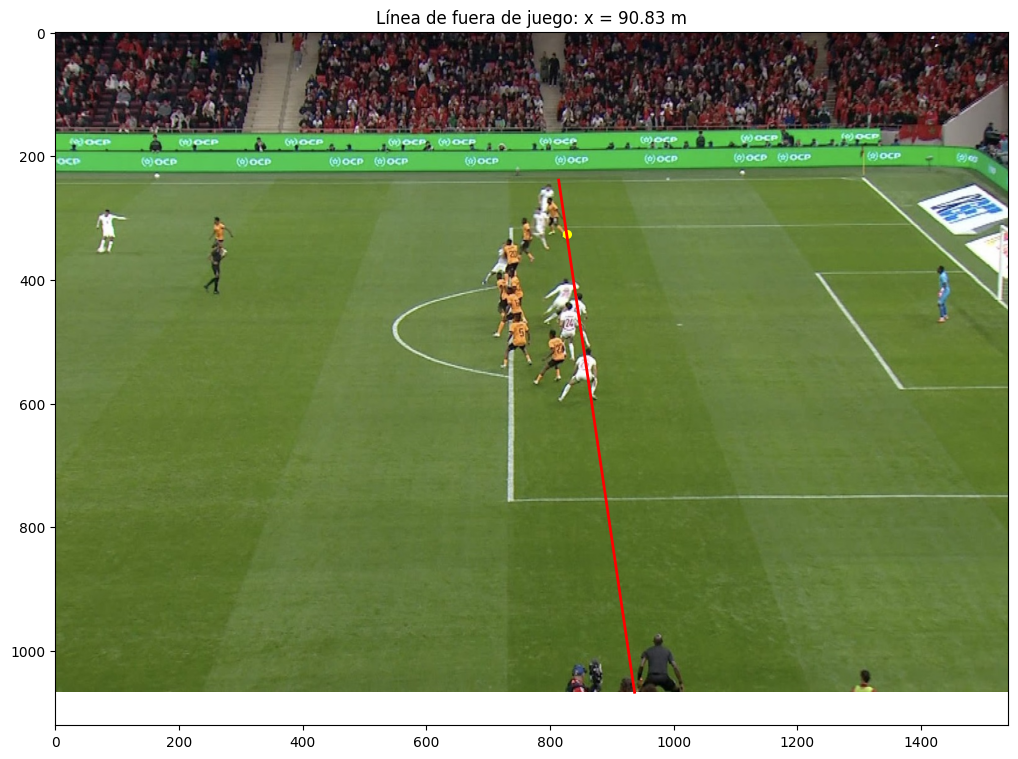

In [ ]:
img = cv2.imread('futbol/test-fuera-de-juego.png')[:, :, ::-1]   # BGR -> RGB
alto, ancho = img.shape[0], img.shape[1]

x_offside = v[0]      # 90.8291: la x del pie del último defensor, en metros

# Puntos de la recta x = x_offside en la cancha, de un lateral (y = 0) al otro (y = 68)
y_cancha = np.arange(0, 68.1, 0.1)
puntos_cancha = np.vstack([x_offside + 0 * y_cancha,      # x constante
                           y_cancha,
                           np.ones(y_cancha.shape[0])])

# Proyección a la foto con H
puntos_img = alc.arroba(H, puntos_cancha)
u = puntos_img[0, :] / puntos_img[2, :]
v_img = puntos_img[1, :] / puntos_img[2, :]

# Nos quedamos con los puntos que caen dentro de la foto
dentro = (u >= 0) & (u < ancho) & (v_img >= 0) & (v_img < alto)

plt.figure(figsize=(14, 9))
plt.imshow(img)
plt.plot(u[dentro], v_img[dentro], color='red', linewidth=2)
plt.scatter(827, 326, c='yellow', s=30)     # pie del último defensor
plt.title('Línea de fuera de juego: x = %.2f m' % x_offside)
plt.show()

### Ejercicio 5 - Cruzando en rojo - Cálculo de velocidad

a) Calcular los parámetros intrínsecos de la cámara a partir de las diferentes vistas de la esquina y las coordenadas de los puntos en el archivo $\texttt{world\_img\_pts.csv}$

In [60]:
import pandas as pd
import os

ruta_csv_ej_5 = os.path.join('salguero', 'world_img_pts.csv')
df = pd.read_csv(ruta_csv_ej_5, sep=';')

array_df = np.array(df)
print(df)
objPts_ej_5 = array_df[:,1:3] # cortando Z a propósito, si no lo veo, no existe 
print(objPts_ej_5)

Hlst_ej_5 = []

for k in range(4):
    indice_col_u = 4 + (2*k) 
    indice_col_v = 5 + (2*k)

    uv_k = array_df[:, indice_col_u: indice_col_v + 1]

    imgPts_ej_5 = np.reshape(uv_k, -1)

    Q_ej_5 = obtenerQ2d(imgPts_ej_5, objPts_ej_5)

    hatU_ej_5, hatSig_ej_5, hatV_ej_5 = alc.svd_reducida(Q_ej_5)

    Hk_ej_5 = np.reshape(hatV_ej_5[:,-1], (3, 3))
    Hlst_ej_5.append(Hk_ej_5)

print(Hk_ej_5.shape)
A_ej_5 = armarA(Hlst_ej_5)
print(A_ej_5.shape)
K_ej_5 = calcularMatrizK2D(A_ej_5)

print(f"\nK:\n{K_ej_5}")


    

   pts    X   Y    Z   u_0  v_0   u_1  v_1   u_2  v_2   u_3  v_3
0    6 -4.0   3  0.0   281  474   255  490   469  581   446  563
1   36  4.0   0  0.0   889  521  1071  577  1147  653  1118  621
2   40  6.5   3  0.1  1139  493  1403  550  1425  625  1396  590
3   41 -5.0  14  0.1   418  385   437  377   627  485   600  466
4   42 -5.0  76  0.1   833  262   997  227  1094  357  1064  331
[[-4.   3. ]
 [ 4.   0. ]
 [ 6.5  3. ]
 [-5.  14. ]
 [-5.  76. ]]
(3, 3)
(8, 6)

K:
[[2.78278008e+03 1.35536578e+03 2.89090323e+02]
 [0.00000000e+00 2.13055733e+02 1.95627005e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]


b) A partir de los puntos $\texttt{gs\_10\_09\_point\_correspondences\_v5.txt}$ calcular la pose de la cámara y reproyectar los puntos sobre la imagen $\texttt{img\_10\_18\_47\_351.jpg}$.

[[ 9.  21. ]
 [-6.  76. ]
 [ 5.   3. ]
 [-4.   0. ]
 [-3.5  0. ]]
[1214.  365.  833.  262.  959.  486.  184.  505.  223.  506.  280.]
R:
 [[ 0.97332984  0.22778923  0.02722312]
 [ 0.04182274 -0.0595125  -0.99735105]
 [-0.22556571  0.97189008 -0.06745206]]

 t:
 [-21.53276372  49.78253768  33.61568763]


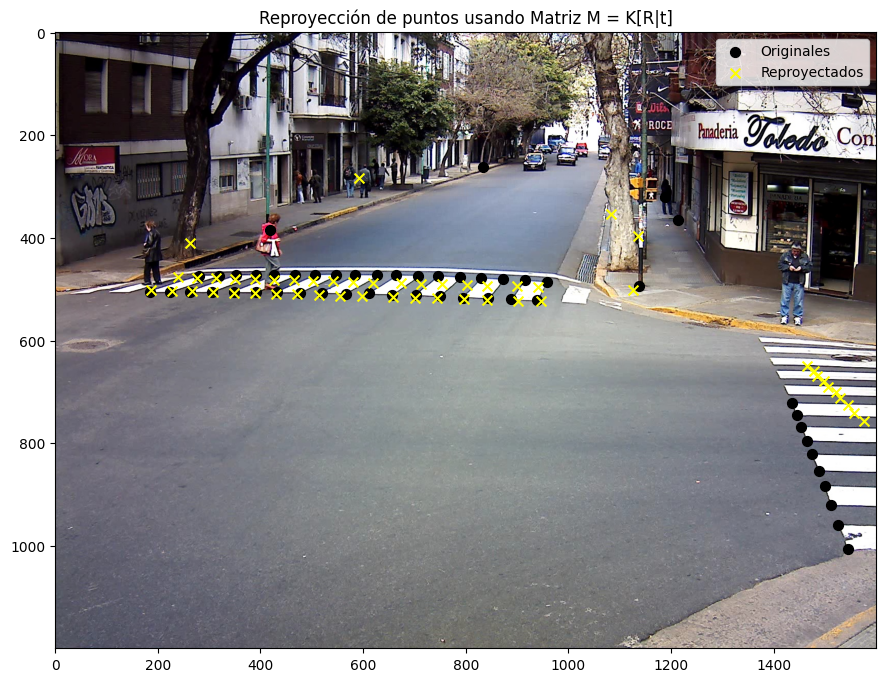

In [63]:
ruta_txt = os.path.join('salguero', 'gs_10_09_point_correspondences_v5.txt')
df_b = pd.read_csv(ruta_txt, sep=r'\s+', header=None)
array_df_2 = np.array(df_b)

objPts_b = alc.transpuesta(array_df_2[1:3, :])
print(objPts_b[:5,:])

uv_b = alc.transpuesta(array_df_2[4:6, :])

# reshape para usar 
imgPts_b = np.reshape(uv_b, -1)
print(imgPts_b[:11])


Q_img_ej_5 = alc.obtenerQ2d(imgPts_b, objPts_b)
H_img_ej_5 = alc.resolverDLT2D(Q_img_ej_5)

R_pose_ej_5, t_pose_ej_5 = alc.obtenerPose2D(H_img_ej_5, K_ej_5)

print("R:\n", R_pose_ej_5)
print("\n t:\n", t_pose_ej_5)



##### K (R(P) + t) 










# Matriz de proyección M = K * [R | t]
Rt = alc.armar_Rt(R_pose_ej_5, t_pose_ej_5)
M = alc.arroba(K_ej_5, Rt)

# Puntos físicos 3D (X, Y, Z) 
N = array_df_2.shape[1]
XYZ = array_df_2[1:4, :] # Filas 1, 2 y 3 corresponden a X, Y, Z
unos = np.ones((1, N))
P_homogeneos = np.vstack((XYZ, unos)) # Dimensión resultante: 4 x N

# 3. Reproyectar: M (3x4) x P_homogeneos (4xN)
p_reproyectados = alc.arroba(M, P_homogeneos) # Dimensión resultante: 3 x N

# 4. Dividir por la tercera coordenada (z o w) para volver al plano del píxel (u, v)
u_proy = p_reproyectados[0, :] / p_reproyectados[2, :]
v_proy = p_reproyectados[1, :] / p_reproyectados[2, :]

# 5. Visualización
ruta_img = os.path.join('salguero', 'img_10_18_47_351.jpg')
img = mpimg.imread(ruta_img)

plt.figure(figsize=(14, 8))
plt.imshow(img)

# Puntos originales del txt en rojo
plt.scatter(uv_b[:, 0], uv_b[:, 1], c='black', marker='o', s=50, label='Originales')

# Puntos reproyectados en verde (cruces)
plt.scatter(u_proy, v_proy, c='Yellow', marker='x', s=50, label='Reproyectados')

plt.legend()
plt.title("Reproyección de puntos usando Matriz M = K[R|t]")
plt.show()





c) Calcular la velocidad de los dos primeros vehículos (taxi y camioneta) y de la señora de buzo rojo que cruza la calle. Graficar las velocidades en un plot temporal a lo largo de la secuencia.

In [ ]:
carpeta = os.path.join('salguero', 'gs_dataset')
fotos = sorted([f for f in os.listdir(carpeta) if f.endswith('.jpg')])
tiempos = np.array([alc.tiempoDesdeNombre(f) for f in fotos])
tiempos = tiempos - tiempos[0]                           # que empiece en t = 0

#  Píxeles marcados a mano 
# Índices de la lista 'fotos' (0 = img_10_18_47_351, ..., 45 = img_10_18_52_546)

# Señora de buzo rojo: punto medio entre los pies
idx_senora = [0, 5, 10, 15, 20, 25, 30, 35, 39, 45]
pix_senora = np.array([[420, 492], [505, 495], [557, 492], [648, 491], [714, 490],
                       [781, 485], [835, 484], [894, 484], [937, 484], [994, 484]])

# Taxi: rueda delantera del lado izquierdo de la imagen, donde toca el piso
idx_taxi = [30, 33, 36, 39, 42, 45]
pix_taxi = np.array([[685, 363], [637, 387], [570, 415],
                     [485, 452], [375, 502], [245, 557]])

# Camioneta: rueda delantera del lado izquierdo de la imagen, donde toca el piso
idx_camioneta = [30, 33, 36, 39, 42, 45]
pix_camioneta = np.array([[902, 328], [880, 340], [855, 360],
                          [820, 382], [780, 415], [735, 445]])

# 3) Píxel -> calle con H^{-1}
H_inv = alc.inversa(H_img)

for nombre, pix, idx in [('Taxi', pix_taxi, idx_taxi),
                         ('Camioneta', pix_camioneta, idx_camioneta),
                         ('Señora', pix_senora, idx_senora)]:
    v, v_media = alc.calcularVelocidades(pix, idx, H_inv, tiempos)
    print(nombre)
    print('  velocidades entre fotos (km/h):', np.round(v * 3.6, 1))
    print('  velocidad media: %.1f km/h\n' % (v_media * 3.6))

Taxi
  velocidades entre fotos (km/h): [51.1 53.5 53.5 47.6 39.8]
  velocidad media: 49.0 km/h

Camioneta
  velocidades entre fotos (km/h): [41.8 64.9 56.6 58.4 42.7]
  velocidad media: 52.6 km/h

Señora
  velocidades entre fotos (km/h): [7.4 4.  4.9 5.9 6.5 4.2 4.6 4.8 3.9]
  velocidad media: 5.0 km/h



### Ejercicio 6 - Aterrizaje suave

a) Aplicar POSIT para encontrar la pose ($\mathbf{R}$ y $\mathbf{t}$) de la cámara del Drone a partir de la imagen $\texttt{row\_00248.png}$. La cámara tiene la matriz intrínseca $\mathbf{K}$. 

b) Estimar la matriz de rotación y traslación para ubicar al drone exactamente sobre la letra H y que la cámara la vea vertical (el punto blanco marca la parte superior izquierda)

In [30]:
import pandas as pd
import os

img_vecs = np.array([
    [525.0, 1003.0], # 0: Centro
    [402.0, 1097.0], # 1: Extremo sup izq
    [392.0, 945.0],  # 2: Extremo sup der
    [644.0, 912.0],  # 3: Extremo inf der
    [656.0, 1061.0]  # 4: Extremo inf izq
])

ruta_obj = os.path.join('heli', 'object_points.csv')
ruta_K = os.path.join('heli', 'K.csv')

df_obj = pd.read_csv(ruta_obj, sep=';', header=0)
obj_vecs = df_obj.iloc[:, 1:4].values

df_K = pd.read_csv(ruta_K, sep=';', header=None)
K = df_K.values


print("Dim obj_vecs:", obj_vecs.shape) # (5, 3)
print("Dim img_vecs:", img_vecs.shape) # (5, 2)
print("Dim K:", K.shape)               #(3, 3)


R_final, t_final = alc.aplicarPOSIT(
    obj_vecs=obj_vecs, 
    img_vecs=img_vecs, 
    K=K, 
    MaxIt=100, 
    atol=1e-6
)

print(R_final)
print(t_final)

Dim obj_vecs: (5, 3)
Dim img_vecs: (5, 2)
Dim K: (3, 3)
la diferencia fue menor antes de terminar MaxIt, RMS_1 = 33.67897046136197, RMS_2 = 16.138788436037437
[[-0.11038457 -0.89118188 -0.44001148]
 [-0.94388997  0.23264873 -0.23440627]
 [ 0.31126673  0.38944759 -0.86685846]]
[-0.57991907  0.76305141  3.72743228]
